# Task 2 - 03 Model and Training

## Objective
Train a CNN that classifies the 6 classes (fresh/rotten x apple/banana/orange) and save it as an artifact that the Task 3 app can load.

## Short theory
* **CNN** - convolution layers learn filters (edges -> textures -> parts of objects); pooling shrinks the image; a final linear layer outputs one score per class.
* **Transfer learning** - ResNet18 was already trained on 1.2 million ImageNet photos, so it already "knows" edges, textures and colours. We keep these layers and only replace the last layer (1000 -> number of our classes). This needs much less data and time than training from scratch.
* **Warm-up (freezing)** - in the first epoch only the new head learns (backbone frozen), then everything is fine-tuned with a small learning rate.
* **Loss** - cross-entropy (optionally class-weighted). **Optimizer** - AdamW (Adam + weight decay regularization). **Scheduler** - cosine annealing slowly lowers the learning rate. **Early stopping** - stop when validation accuracy no longer improves; the best epoch is kept.

In [1]:
# --- Setup: find the project root (the folder that contains "src") so imports work ---
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.task2 import config

warnings.filterwarnings("ignore", category=FutureWarning)
config.ensure_out_dir()
print("Project root :", ROOT.name)
print("Data folder  :", config.DATA_DIR)
print("Output folder:", config.OUT_DIR)

import os
import torch
from src.task2 import data_utils, dataset, model as model_lib, train_utils, viz

Project root : FCVG101_Coursework
Data folder  : C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\data\raw
Output folder: C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\outputs


## Step 1 - Load the split and set the seed
We read `splits.csv` written by notebook 02, so training uses exactly the same split as everything else.

In [2]:
train_utils.seed_everything(config.SEED)
device = train_utils.get_device()
splits = data_utils.load_splits(config.OUT_DIR)
class_names = data_utils.class_names_from_df(splits)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("Classes:", class_names)
print(splits["split"].value_counts().to_dict())

Device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU
Classes: ['fresh_apple', 'fresh_banana', 'fresh_orange', 'rotten_apple', 'rotten_banana', 'rotten_orange']
{'train': 870, 'val': 170, 'test': 153}


## Step 2 - DataLoaders and class weights
The number of classes is read from the data, not hard-coded. The class weights make errors on rare classes count more in the loss.

In [3]:
loaders = dataset.make_dataloaders(splits)
class_weights = dataset.compute_class_weights(splits[splits["split"] == "train"], len(class_names))
print({name: round(float(w), 3) for name, w in zip(class_names, class_weights)})
if not config.USE_CLASS_WEIGHTS:
    class_weights = None

{'fresh_apple': 0.986, 'fresh_banana': 0.993, 'fresh_orange': 1.098, 'rotten_apple': 1.021, 'rotten_banana': 0.993, 'rotten_orange': 0.924}


## Step 3 - Build the model (ResNet18 transfer learning)
**What:** `build_model` loads ImageNet weights and swaps the final `fc` layer for `Dropout -> Linear(512, num_classes)`.
**Why:** the pretrained backbone provides ready-made visual features; the small new head is the only part that has to be learned from scratch.

In [4]:
model = model_lib.build_model(num_classes=len(class_names))
trainable, total = model_lib.count_parameters(model)
print(f"Total parameters    : {total:,}")
print(f"Trainable (all)     : {trainable:,}")

model_lib.set_backbone_trainable(model, False)                    # what the warm-up epoch trains
print(f"Trainable (warm-up) : {model_lib.count_parameters(model)[0]:,}   <- only the new head")
model_lib.set_backbone_trainable(model, True)
print("\nNew classifier head:", model.fc, sep="\n")

Total parameters    : 11,179,590
Trainable (all)     : 11,179,590
Trainable (warm-up) : 3,078   <- only the new head

New classifier head:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=512, out_features=6, bias=True)
)


## Step 4 - Hyper-parameters
All values come from `src/task2/config.py` (one place, easy to document and change).

In [5]:
pd.DataFrame({"value": config.hyperparameters()})

,value
architecture,resnet18
pretrained,True
img_size,224
batch_size,32
epochs,8
learning_rate,0.0003
weight_decay,0.0001
dropout,0.2
freeze_epochs,1
patience,4


## Step 5 - Training loop
**What:** `fit` runs the epoch loop: train on the training set, measure loss/accuracy on the validation set, step the LR scheduler and save `model_best.pt` whenever validation accuracy improves. It also writes `model_meta.json` (class names, image size, normalization, architecture) and `history.json`.
**Why:** the metadata file lets the Task 3 app rebuild the model and preprocess images exactly like in training.

In [6]:
meta = model_lib.make_meta(class_names)
history = train_utils.fit(model, loaders, class_weights=class_weights,
                          out_dir=config.OUT_DIR, meta=meta, log_fn=print)
print("\nBest epoch:", history["best_epoch"], "| best validation accuracy:", round(history["best_val_acc"], 4))
print("Average seconds per epoch:", round(float(np.mean(history["epoch_seconds"])), 1))

epoch 01/8 | train loss 1.7422 acc 0.2575 | val loss 1.5623 acc 0.3882 | 11.4s


epoch 02/8 | train loss 0.3554 acc 0.8874 | val loss 0.3919 acc 0.8882 | 7.6s


epoch 03/8 | train loss 0.1197 acc 0.9575 | val loss 0.2062 acc 0.9235 | 7.2s


epoch 04/8 | train loss 0.0610 acc 0.9793 | val loss 0.0840 acc 0.9706 | 7.1s


epoch 05/8 | train loss 0.0457 acc 0.9874 | val loss 0.0692 acc 0.9765 | 7.1s


epoch 06/8 | train loss 0.0310 acc 0.9920 | val loss 0.0361 acc 0.9941 | 7.0s


epoch 07/8 | train loss 0.0272 acc 0.9931 | val loss 0.0493 acc 0.9824 | 6.9s


epoch 08/8 | train loss 0.0274 acc 0.9931 | val loss 0.0449 acc 0.9824 | 7.0s

Best epoch: 6 | best validation accuracy: 0.9941
Average seconds per epoch: 7.6


## Step 6 - Learning curves
How to read them: both losses should go down; a growing gap between train and validation accuracy means overfitting.

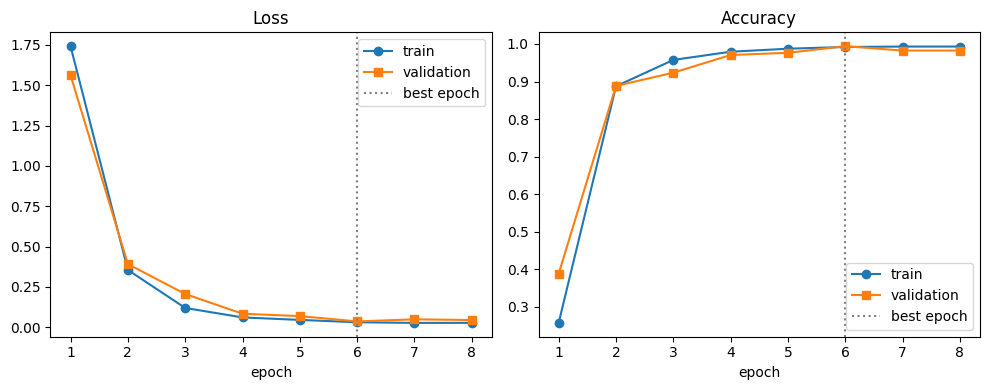

,train_loss,train_acc,val_loss,val_acc,lr
0,1.7422,0.2575,1.5623,0.3882,0.0003
1,0.3554,0.8874,0.3919,0.8882,0.0003
2,0.1197,0.9575,0.2062,0.9235,0.0003
3,0.0610,0.9793,0.0840,0.9706,0.0002
4,0.0457,0.9874,0.0692,0.9765,0.0001
5,0.0310,0.9920,0.0361,0.9941,0.0001
6,0.0272,0.9931,0.0493,0.9824,0.0000
7,0.0274,0.9931,0.0449,0.9824,0.0000


In [7]:
viz.plot_learning_curves(history, save_path=config.OUT_DIR / "learning_curves.png")
plt.show()
pd.DataFrame({k: history[k] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}).round(4)

## Step 7 - Saved artifacts
Check that the saved model can be reloaded the way the Task 3 app will do it.

In [8]:
from src.task2.predict import load_model

reloaded = load_model(config.OUT_DIR)
print("Reloaded architecture:", reloaded.meta["architecture"], "| classes:", reloaded.meta["class_names"])
for name in ["model_best.pt", "model_meta.json", "history.json", "splits.csv", "class_names.json"]:
    path = config.OUT_DIR / name
    print(f"{name:18s}", "OK" if path.exists() else "MISSING", f"({path.stat().st_size / 1024:.0f} KB)" if path.exists() else "")

Reloaded architecture: resnet18 | classes: ['fresh_apple', 'fresh_banana', 'fresh_orange', 'rotten_apple', 'rotten_banana', 'rotten_orange']
model_best.pt      OK (43748 KB)
model_meta.json    OK (0 KB)
history.json       OK (1 KB)
splits.csv         OK (582 KB)
class_names.json   OK (0 KB)


## Step 8 (optional) - Baseline CNN from scratch
Set `RUN_BASELINE = True` to train the small `SimpleCNN` (4 conv blocks, no pretraining) with the same settings, so the report can show *why transfer learning helps*. Default is off to save time.

In [9]:
RUN_BASELINE = os.environ.get("TASK2_RUN_BASELINE", "0") == "1"      # set to True to run the baseline

if RUN_BASELINE:
    train_utils.seed_everything(config.SEED)
    baseline = model_lib.build_model(len(class_names), architecture="simplecnn")
    base_meta = model_lib.make_meta(class_names, architecture="simplecnn", pretrained=False)
    base_hist = train_utils.fit(baseline, loaders, class_weights=class_weights, out_dir=config.OUT_DIR,
                                prefix="simplecnn_", meta=base_meta, log_fn=print)
    criterion = torch.nn.CrossEntropyLoss()
    rows = {}
    for name, net, hist in [("ResNet18 (pretrained)", model, history), ("SimpleCNN (scratch)", baseline, base_hist)]:
        _, test_acc = train_utils.evaluate_epoch(net, loaders["test"], criterion, device)
        rows[name] = {"parameters": model_lib.count_parameters(net)[1], "best_val_acc": hist["best_val_acc"],
                      "test_acc": test_acc, "sec_per_epoch": float(np.mean(hist["epoch_seconds"]))}
    comparison = pd.DataFrame(rows).T.round(4)
    comparison.to_csv(config.OUT_DIR / "baseline_comparison.csv")
    display(comparison)
else:
    print("Baseline skipped (RUN_BASELINE is False).")

epoch 01/8 | train loss 1.7917 acc 0.2264 | val loss 1.7976 acc 0.2706 | 6.4s


epoch 02/8 | train loss 1.2102 acc 0.5724 | val loss 0.8640 acc 0.7235 | 7.2s


epoch 03/8 | train loss 0.9304 acc 0.7011 | val loss 0.8166 acc 0.7412 | 6.8s


epoch 04/8 | train loss 0.8287 acc 0.7644 | val loss 0.6894 acc 0.7824 | 7.1s


epoch 05/8 | train loss 0.7699 acc 0.7644 | val loss 0.6537 acc 0.8235 | 7.0s


epoch 06/8 | train loss 0.7146 acc 0.7977 | val loss 0.5941 acc 0.8647 | 6.9s


epoch 07/8 | train loss 0.7165 acc 0.7885 | val loss 0.5581 acc 0.8647 | 7.1s


epoch 08/8 | train loss 0.6685 acc 0.8023 | val loss 0.5525 acc 0.8647 | 7.0s


,parameters,best_val_acc,test_acc,sec_per_epoch
ResNet18 (pretrained),11179590.0,0.9941,0.9869,7.6408
SimpleCNN (scratch),390918.0,0.8647,0.8889,6.9428


## Summary / Observations
* **Model:** ResNet18 pretrained on ImageNet; the last layer is replaced by `Dropout(0.2) -> Linear(512, 6)`. 11,179,590 parameters in total; only 3,078 are trainable during the 1-epoch warm-up (the new head), then all layers are fine-tuned.
* **Hyper-parameters:** AdamW, lr 3e-4 with cosine schedule, weight decay 1e-4, batch size 32, up to 8 epochs with early stopping (patience 4), class-weighted cross-entropy, mixed precision, seed 42.
* **Training:** best epoch **6** with validation accuracy **0.994** (169 of 170). Epoch 1 is slow to learn (val acc 0.39) because only the head is trained; after unfreezing, validation accuracy jumps to 0.89 and reaches 0.97-0.99 by epochs 4-6. About **7.6 s per epoch** (first epoch 11 s because of CUDA warm-up) on an RTX 4060 with `num_workers = 0` (4 workers were tested and were slower: 22 s vs 5 s for one pass over the data, because on Windows the workers are re-created every epoch).
* **Learning curves:** train and validation curves move together; at the end train accuracy is 0.993 and validation 0.982-0.994, so there is no sign of strong overfitting. Validation loss flattens from epoch 6.
* **Baseline comparison:** SimpleCNN (4 conv blocks, 390,918 parameters, trained from scratch for the same 8 epochs) reached validation accuracy **0.865** and test accuracy **0.889**, versus **0.994** and **0.987** for ResNet18. The baseline was still improving at epoch 8 (train accuracy only 0.80), so part of the gap is lack of training time, but this is exactly the benefit of transfer learning: pretrained features give a high accuracy after a few epochs on only 870 training images. Time per epoch is similar (7.6 s vs 6.9 s) because data loading dominates.
* **Next step:** notebook 04 evaluates the saved model on the untouched test split.